In [1]:
%pip install xarray numpy pandas matplotlib

import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Note: you may need to restart the kernel to use updated packages.


In [4]:
%pip install netCDF4

ds = xr.open_dataset("../data/global-marine-litter-2020.nc")

print(ds)

Note: you may need to restart the kernel to use updated packages.
<xarray.Dataset> Size: 2GB
Dimensions:  (traj: 387600, obs: 733)
Coordinates:
    time     (obs) datetime64[ns] 6kB ...
Dimensions without coordinates: traj, obs
Data variables:
    lon      (traj, obs) float32 1GB ...
    lat      (traj, obs) float32 1GB ...
Attributes:
    title:         Global Marine Litter trajectories
    description:   Combined monthly releases of 32300 particles for 2020.
    institution:   FLorida State University Center for Ocean-Atmospheric Pred...
    references:    Chassignet, E. P., Xu, X., & Zavala-Romero, O. (2021), Tra...
    date_created:  2022-03-08T17:21:58.252213


In [5]:
# Gets the first and last observation of the time variable. as well as the maximum number of observations in the dataset.
print("First observation:", ds.time.values[0]) 
print("Last observation:", ds.time.values[-1])
print("Number of observations:", len(ds.time))

First observation: 2020-01-01T00:00:00.000000000
Last observation: 2022-01-02T00:00:00.000000000
Number of observations: 733


In [6]:
# Calculate the time difference between the first two observations in hours
time_difference = ds.time.values[1] - ds.time.values[0]

print("Time interval:", time_difference / np.timedelta64(1, 'h'), "hours")

Time interval: 24.0 hours


In [7]:
# Get the first observation of latitude and longitude for each particle in the dataset
start_lat = ds.lat.isel(obs=0)
start_lon = ds.lon.isel(obs=0)

# Print the range of the first observation of latitude and longitude
print("Starting latitude range:", 
      float(start_lat.min()), float(start_lat.max()))

print("Starting longitude range:", 
      float(start_lon.min()), float(start_lon.max()))

Starting latitude range: -55.36840057373047 69.87090301513672
Starting longitude range: -175.53689575195312 179.35499572753906


In [8]:
# Create a mask for particles that start in the Atlantic Ocean
atlantic_mask = (
    (start_lat >= -60) &
    (start_lat <= 70) &
    (start_lon >= -100) &
    (start_lon <= 20)
)

# Print the total number of particles and the number of particles that start in the Atlantic Ocean
print("Total particles:", ds.sizes["traj"])
print("Particles starting in Atlantic:", int(atlantic_mask.sum()))

Total particles: 387600
Particles starting in Atlantic: 9306


In [9]:
# Create a new dataset that only contains particles that start in the Atlantic Ocean
atlantic_ds = ds.isel(traj=atlantic_mask)

print(atlantic_ds)

<xarray.Dataset> Size: 55MB
Dimensions:  (traj: 9306, obs: 733)
Coordinates:
    time     (obs) datetime64[ns] 6kB 2020-01-01 2020-01-02 ... 2022-01-02
Dimensions without coordinates: traj, obs
Data variables:
    lon      (traj, obs) float32 27MB ...
    lat      (traj, obs) float32 27MB ...
Attributes:
    title:         Global Marine Litter trajectories
    description:   Combined monthly releases of 32300 particles for 2020.
    institution:   FLorida State University Center for Ocean-Atmospheric Pred...
    references:    Chassignet, E. P., Xu, X., & Zavala-Romero, O. (2021), Tra...
    date_created:  2022-03-08T17:21:58.252213


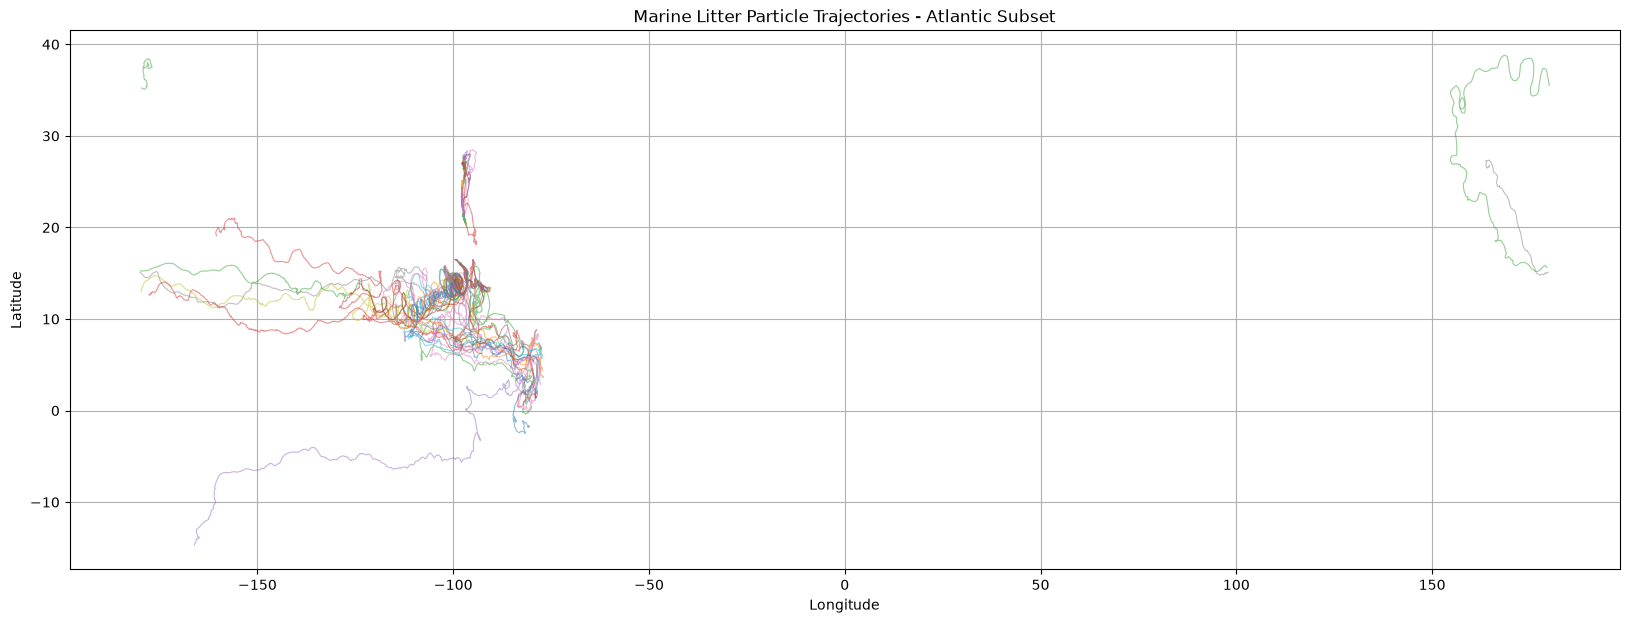

In [10]:
plt.figure(figsize=(20, 7))

sample = atlantic_ds

for i in range(50):
    lon = sample.lon.values[i, :].copy()
    lat = sample.lat.values[i, :].copy()

    # Break lines when particles cross the International Date Line
    jumps = np.where(np.abs(np.diff(lon)) > 180)[0] + 1

    lon[jumps] = np.nan
    lat[jumps] = np.nan

    plt.plot(lon, lat, alpha=0.5, linewidth=0.8)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Marine Litter Particle Trajectories - Atlantic Subset")
plt.grid()
plt.show()

In [11]:
# Get all particle coordinates
lat = ds.lat.values
lon = ds.lon.values

# Identify valid positions
valid = np.isfinite(lat) & np.isfinite(lon)

# Find the first valid observation for each particle
first_indices = valid.argmax(axis=1)

particle_indices = np.arange(ds.sizes["traj"])

# Extract each particle's starting coordinates
start_lat_all = lat[particle_indices, first_indices]
start_lon_all = lon[particle_indices, first_indices]

# Exclude particles without valid positions
has_data = valid.any(axis=1)

# Identify particles starting in the Atlantic
atlantic_mask_all = (
    has_data &
    (start_lat_all >= -60) &
    (start_lat_all <= 70) &
    (start_lon_all >= -100) &
    (start_lon_all <= 20)
)

print("Total particles:", ds.sizes["traj"])
print("Particles starting in Atlantic:", int(atlantic_mask_all.sum()))

Total particles: 387600
Particles starting in Atlantic: 111672


In [12]:
atlantic_ds_valid = ds.isel(traj=atlantic_mask_all)

print(atlantic_ds_valid)

<xarray.Dataset> Size: 655MB
Dimensions:  (traj: 111672, obs: 733)
Coordinates:
    time     (obs) datetime64[ns] 6kB 2020-01-01 2020-01-02 ... 2022-01-02
Dimensions without coordinates: traj, obs
Data variables:
    lon      (traj, obs) float32 327MB -99.5 -99.24 -98.98 ... -49.7 -49.71
    lat      (traj, obs) float32 327MB 16.48 16.49 16.42 ... 0.02313 0.02841
Attributes:
    title:         Global Marine Litter trajectories
    description:   Combined monthly releases of 32300 particles for 2020.
    institution:   FLorida State University Center for Ocean-Atmospheric Pred...
    references:    Chassignet, E. P., Xu, X., & Zavala-Romero, O. (2021), Tra...
    date_created:  2022-03-08T17:21:58.252213


In [13]:
# Extract particle coordinates
atlantic_lat = atlantic_ds_valid.lat.values
atlantic_lon = atlantic_ds_valid.lon.values

atlantic_valid = np.isfinite(atlantic_lat) & np.isfinite(atlantic_lon)

start_lat = start_lat_all[atlantic_mask_all]
start_lon = start_lon_all[atlantic_mask_all]

# Correct longitude differences across the International Date Line
dlon = np.radians(
    (atlantic_lon - start_lon[:, None] + 180) % 360 - 180
)

dlat = np.radians(atlantic_lat) - np.radians(start_lat[:, None])

a = (np.sin(dlat / 2)**2 +
     np.cos(np.radians(start_lat[:, None])) *
     np.cos(np.radians(atlantic_lat)) *
     np.sin(dlon / 2)**2)

displacement = 6371 * 2 * np.arctan2(
    np.sqrt(a),
    np.sqrt(1 - a)
)

displacement[~atlantic_valid] = np.nan

print("Number of particles:", len(displacement))
print("Displacement array shape:", displacement.shape)
print("Valid starting positions:", atlantic_valid.any(axis=1).sum())

Number of particles: 111672
Displacement array shape: (111672, 733)
Valid starting positions: 111672


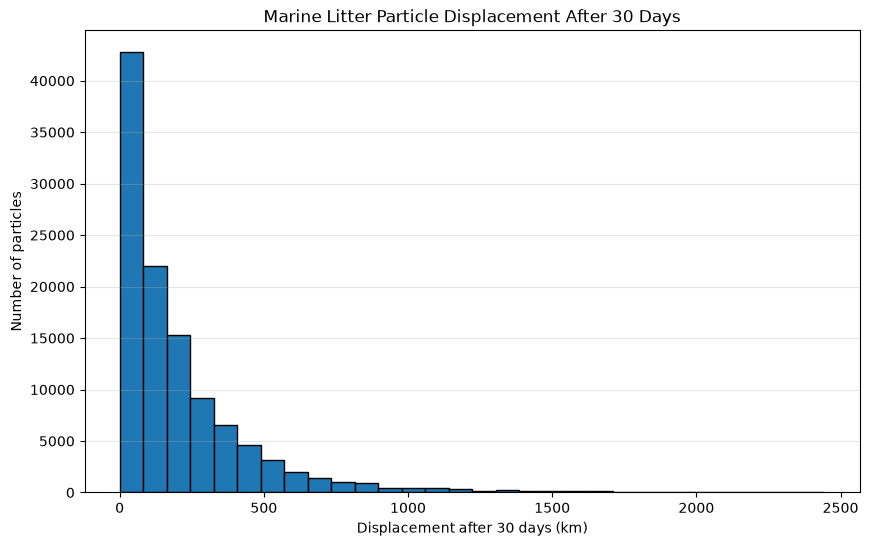

In [14]:
atlantic_first_indices = atlantic_valid.argmax(axis=1)

# Select displacement 30 days after each particle's release
target_indices = atlantic_first_indices + 30

# Keep particles with a valid observation 30 days later
available = target_indices < atlantic_ds_valid.sizes["obs"]

particle_ids = np.arange(len(atlantic_first_indices))[available]
target_days = target_indices[available]

valid_30 = atlantic_valid[particle_ids, target_days]

distance_30 = displacement[particle_ids[valid_30],
                            target_days[valid_30]]

# Plot histogram
plt.figure(figsize=(10, 6))

plt.hist(distance_30, bins=30, edgecolor="black")

plt.xlabel("Displacement after 30 days (km)")
plt.ylabel("Number of particles")
plt.title("Marine Litter Particle Displacement After 30 Days")

plt.grid(axis="y", alpha=0.3)
plt.show()

Day 0 average per occupied hexagon: 191.7
Day 30 average per occupied hexagon: 60.66


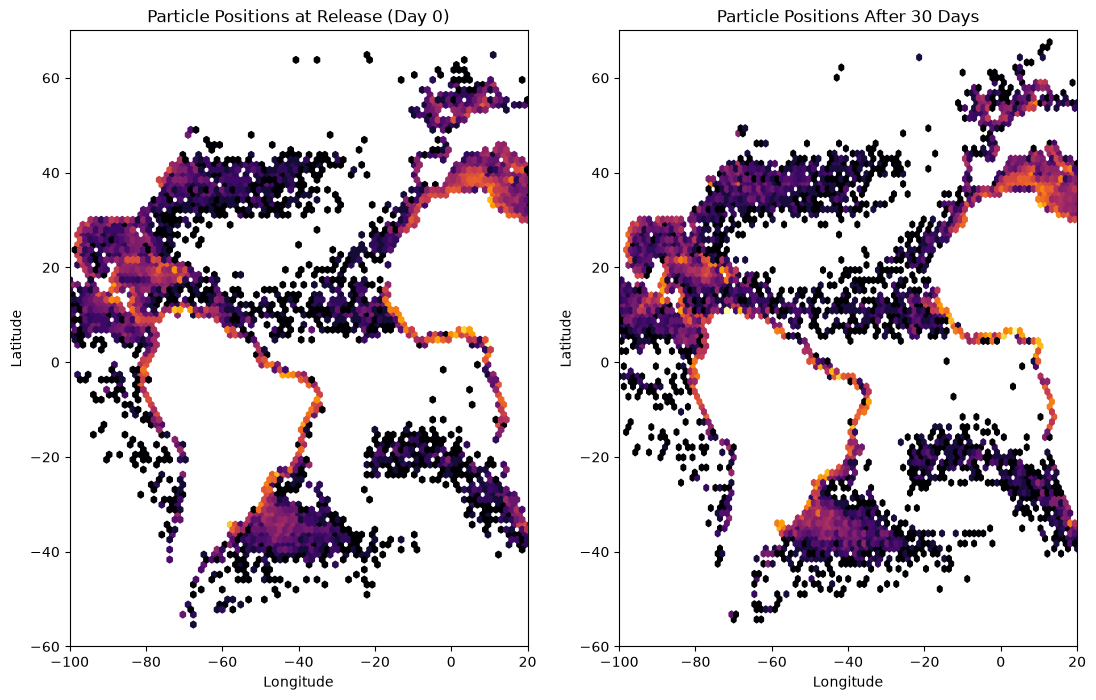

In [15]:
lat_0= lat[particle_ids, atlantic_first_indices[particle_ids]]
lon_0 = lon[particle_ids, atlantic_first_indices[particle_ids]]

# Get particle positions 30 days after release
lon_30 = lon[particle_ids, target_days]
lat_30 = lat[particle_ids, target_days]

# Keep positions within our Atlantic study region
atlantic_region = (
    (lon_30 >= -100) & (lon_30 <= 20) &
    (lat_30 >= -60) & (lat_30 <= 70)
)

lon_plot_0 = lon_0[atlantic_region]
lat_plot_0 = lat_0[atlantic_region]

lon_plot_30 = lon_30[atlantic_region]
lat_plot_30 = lat_30[atlantic_region]

fig,axes = plt.subplots(1, 2,figsize=(13, 8))

#Day 0
hb1 = axes[0].hexbin(
    lon_plot_0,
    lat_plot_0,
    gridsize=100,
    mincnt=1,
    bins='log',
    cmap='inferno'
    
)

axes[0].set_title("Particle Positions at Release (Day 0)")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
axes[0].set_xlim(-100, 20)
axes[0].set_ylim(-60, 70)

hb2 = axes[1].hexbin(
    lon_plot_30,
    lat_plot_30,
    gridsize=100,
    mincnt=1,
    bins='log',
    cmap='inferno'
)

axes[1].set_title("Particle Positions After 30 Days")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")
axes[1].set_xlim(-100, 20)
axes[1].set_ylim(-60, 70)

print("Day 0 average per occupied hexagon:",
      round(111185 / 580, 2))

print("Day 30 average per occupied hexagon:",
      round(111185 / 1833, 2))

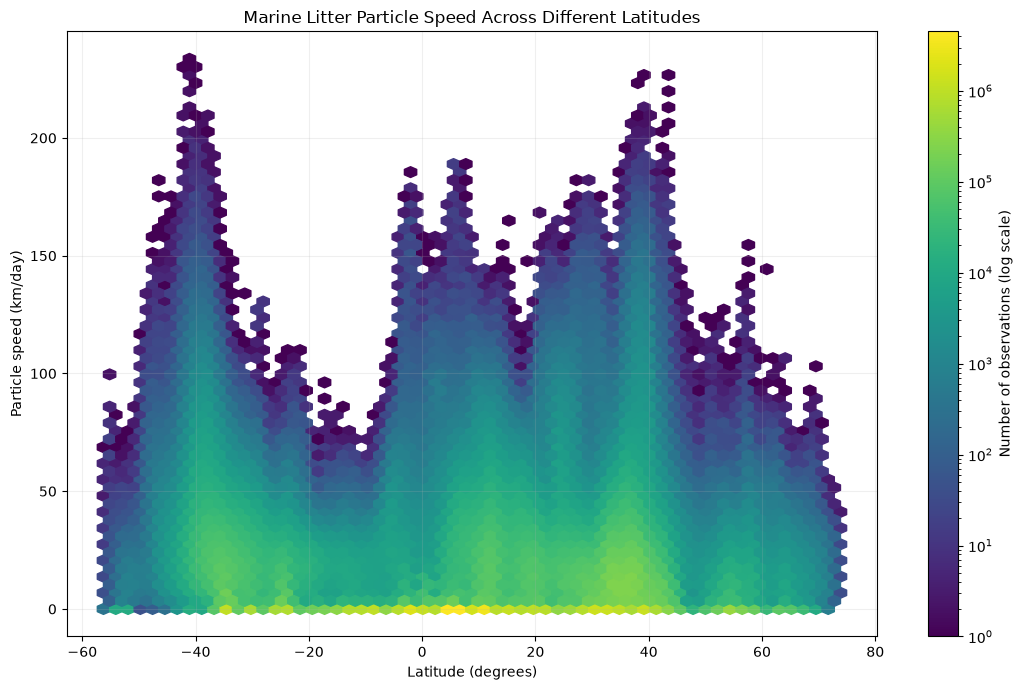

In [16]:
# Coordinates on consecutive days
lat1 = np.radians(atlantic_lat[:, :-1])
lat2 = np.radians(atlantic_lat[:, 1:])

lon1 = np.radians(atlantic_lon[:, :-1])
lon2 = np.radians(atlantic_lon[:, 1:])

# Calculate daily coordinate differences
dlat = lat2 - lat1
dlon = (lon2 - lon1 + np.pi) % (2 * np.pi) - np.pi

# Haversine distance between consecutive positions
a = (np.sin(dlat / 2)**2 +
     np.cos(lat1) * np.cos(lat2) *
     np.sin(dlon / 2)**2)

daily_distance = 6371 * 2 * np.arctan2(
    np.sqrt(a),
    np.sqrt(1 - a)
)

# Only use consecutive valid positions
valid_pairs = atlantic_valid[:, :-1] & atlantic_valid[:, 1:]

daily_speed = daily_distance[valid_pairs]

# Latitude halfway between consecutive observations
mid_lat = (atlantic_lat[:, :-1] + atlantic_lat[:, 1:]) / 2
speed_lat = mid_lat[valid_pairs]

# Remove invalid values
keep = np.isfinite(daily_speed) & np.isfinite(speed_lat)

daily_speed = daily_speed[keep]
speed_lat = speed_lat[keep]

# Plot speed against latitude
plt.figure(figsize=(11, 7))

plt.hexbin(
    speed_lat,
    daily_speed,
    gridsize=60,
    bins="log",
    mincnt=1,
    cmap="viridis"
)

plt.colorbar(label="Number of observations (log scale)")
plt.xlabel("Latitude (degrees)")
plt.ylabel("Particle speed (km/day)")
plt.title("Marine Litter Particle Speed Across Different Latitudes")

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

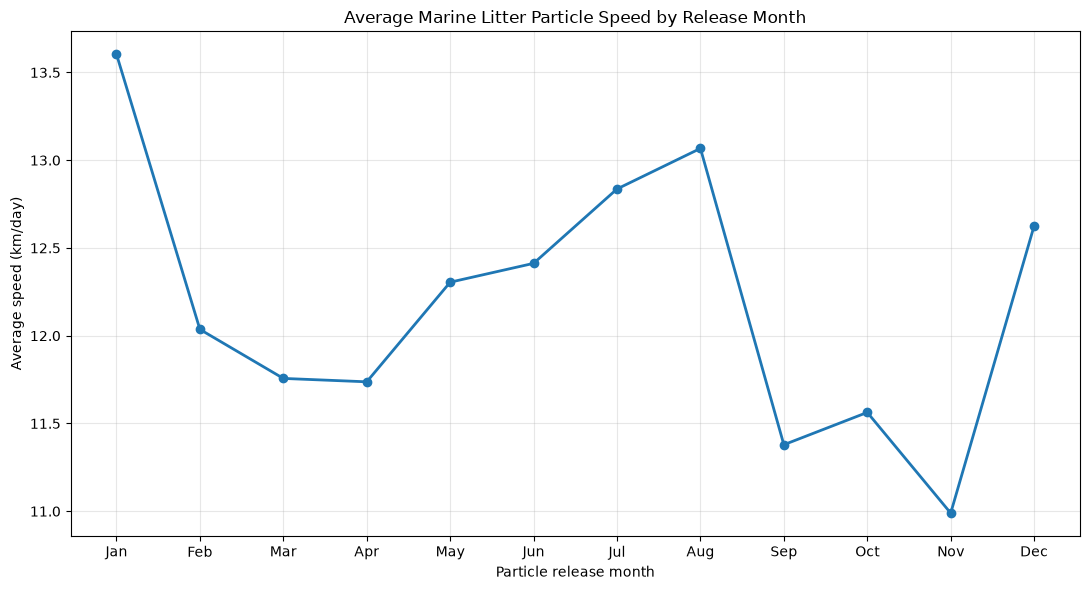

In [17]:
# Calculate average speed during the first 30 days
monthly_speeds = {}
release_months = []

for i in range(len(atlantic_first_indices)):

    start = atlantic_first_indices[i]

    if start + 30 < atlantic_ds.sizes["obs"]:

        speeds = daily_distance[i, start:start + 30]
        pair_valid = valid_pairs[i, start:start + 30]

        usable_speeds = speeds[pair_valid]

        if len(usable_speeds) >= 25:
            monthly_speeds.setdefault(
                int(pd.Timestamp(ds.time.values[start]).month), []
            ).append(np.mean(usable_speeds))

# Calculate monthly averages
months = list(range(1, 13))

average_speeds = [
    np.mean(monthly_speeds[m]) if m in monthly_speeds else np.nan
    for m in months
]

# Plot
plt.figure(figsize=(11, 6))

plt.plot(
    months,
    average_speeds,
    marker="o",
    linewidth=2
)

plt.xticks(months, [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
])

plt.xlabel("Particle release month")
plt.ylabel("Average speed (km/day)")
plt.title("Average Marine Litter Particle Speed by Release Month")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

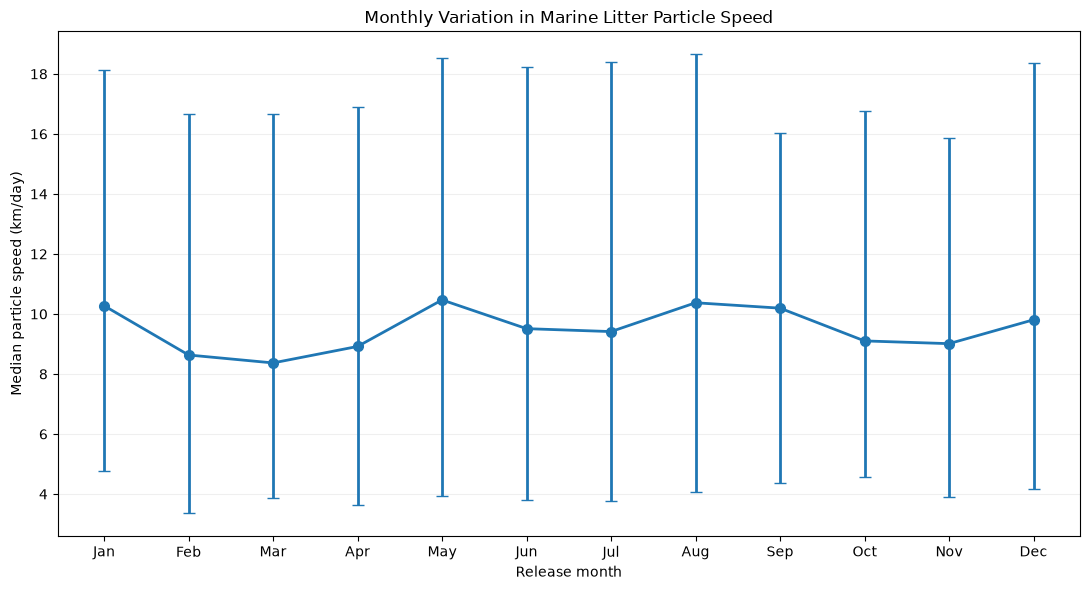

In [33]:
monthly_medians = [
    np.median(monthly_speeds[m]) for m in range(1, 13)
]

monthly_q1 = [
    np.percentile(monthly_speeds[m], 25) for m in range(1, 13)
]

monthly_q3 = [
    np.percentile(monthly_speeds[m], 75) for m in range(1, 13)
]

lower_error = np.array(monthly_medians) - np.array(monthly_q1)
upper_error = np.array(monthly_q3) - np.array(monthly_medians)

plt.figure(figsize=(11, 6))

plt.errorbar(
    range(1, 13),
    monthly_medians,
    yerr=[lower_error, upper_error],
    fmt='o-',
    markersize=7,
    linewidth=2,
    capsize=4
)

plt.xticks(
    range(1, 13),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.xlabel("Release month")
plt.ylabel("Median particle speed (km/day)")
plt.title("Monthly Variation in Marine Litter Particle Speed")

plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

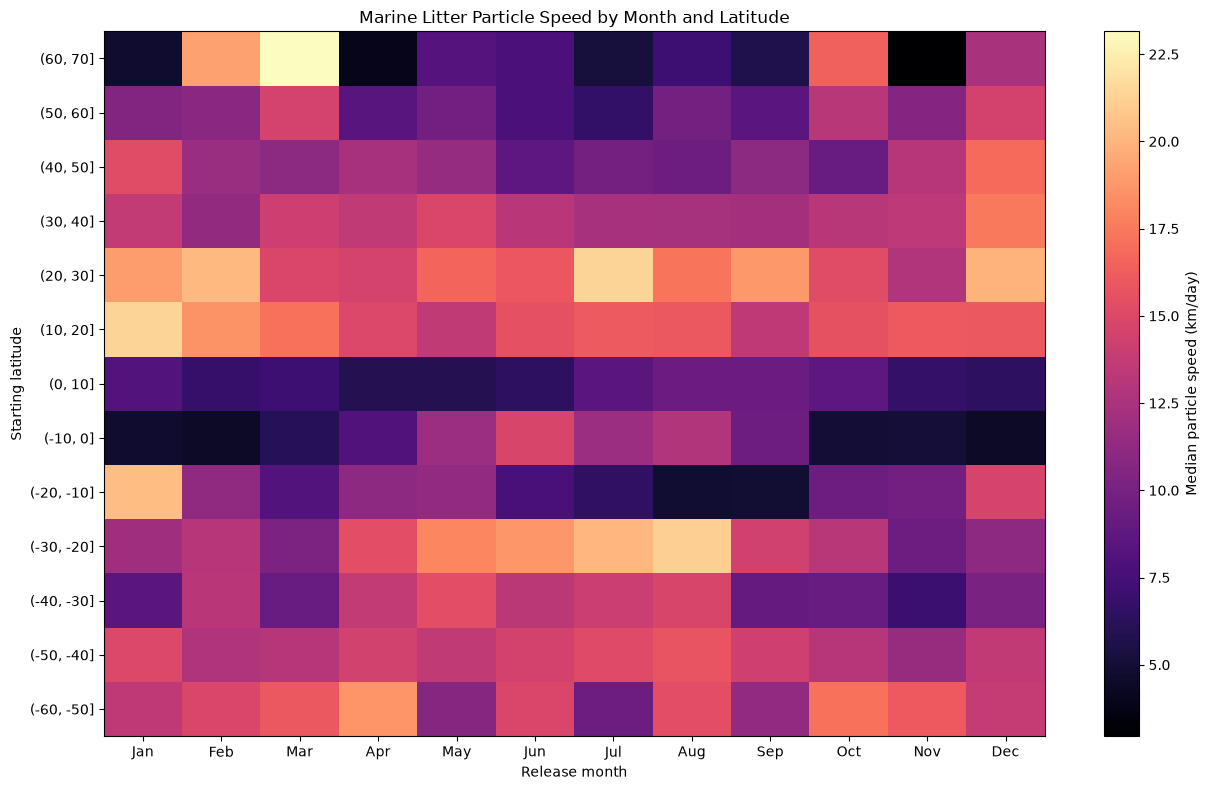

In [36]:
# Calculate average speed during each particle's first 30 days
records = []

for i in range(len(atlantic_first_indices)):

    start = atlantic_first_indices[i]
    end = start + 30

    if end < atlantic_ds_valid.sizes["obs"]:

        speeds = daily_distance[i, start:end]
        pair_valid = valid_pairs[i, start:end]

        usable = speeds[pair_valid]

        if len(usable) >= 25:

            records.append({
                "Month": pd.Timestamp(
                    atlantic_ds_valid.time.values[start]
                ).month,
                "Latitude": start_lat[i],
                "Speed": np.mean(usable)
            })

# Convert results into a DataFrame
speed_df = pd.DataFrame(records)

# Group latitude into 10-degree bands
speed_df["Latitude band"] = pd.cut(
    speed_df["Latitude"],
    bins=np.arange(-60, 81, 10)
)

# Calculate median speed for each month and latitude band
heatmap_data = speed_df.pivot_table(
    index="Latitude band",
    columns="Month",
    values="Speed",
    observed=False
)

# Plot heatmap
plt.figure(figsize=(13, 8))

plt.imshow(
    heatmap_data,
    aspect="auto",
    origin="lower",
    cmap="magma",
    interpolation="nearest"
)

plt.colorbar(label="Median particle speed (km/day)")

plt.xticks(
    range(12),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.yticks(
    range(len(heatmap_data.index)),
    heatmap_data.index.astype(str)
)

plt.xlabel("Release month")
plt.ylabel("Starting latitude")
plt.title("Marine Litter Particle Speed by Month and Latitude")

plt.tight_layout()
plt.show()

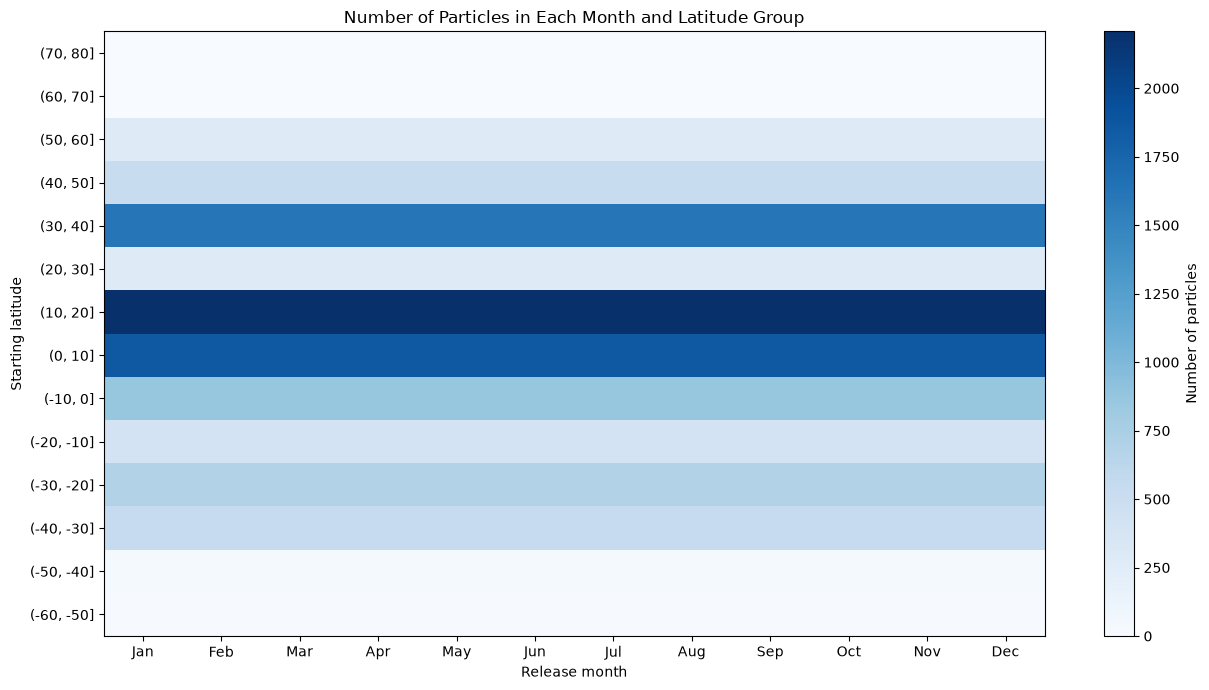

In [37]:
# Count particles in each month and latitude band
count_data = speed_df.pivot_table(
    index="Latitude band",
    columns="Month",
    values="Speed",
    aggfunc="count",
    observed=False
)

plt.figure(figsize=(13, 7))

plt.imshow(
    count_data,
    aspect="auto",
    origin="lower",
    cmap="Blues"
)

plt.colorbar(label="Number of particles")

plt.xticks(
    range(12),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.yticks(
    range(len(count_data.index)),
    count_data.index.astype(str)
)

plt.xlabel("Release month")
plt.ylabel("Starting latitude")
plt.title("Number of Particles in Each Month and Latitude Group")

plt.tight_layout()
plt.show()

In [38]:
from pathlib import Path
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find the monthly Copernicus file
nc_files = list(Path("..").glob("*.nc"))

# Search likely data locations recursively for the monthly Copernicus NetCDF file
nc_files = list(Path("..").rglob("*.nc"))

copernicus_files = [
    f for f in nc_files
    if "P1M" in f.name.upper()
    and "marine-litter" not in f.name.lower()
]

if not copernicus_files:
    raise FileNotFoundError(
        "No monthly Copernicus NetCDF file containing 'P1M' was found. "
        "Place it in the project data folder, or verify its filename."
    )

copernicus_file = copernicus_files[0]
print("Loading:", copernicus_file)

# Load dataset
currents = xr.open_dataset(copernicus_file)

print(currents)

Loading: ..\data\cmems_mod_glo_phy_my_0.083deg_P1M-m_1795028217853.nc
<xarray.Dataset> Size: 81MB
Dimensions:    (time: 25, depth: 1, latitude: 481, longitude: 840)
Coordinates:
  * time       (time) datetime64[ns] 200B 2020-01-01 2020-02-01 ... 2022-01-01
  * depth      (depth) float32 4B 0.494
  * latitude   (latitude) float32 2kB 10.0 10.08 10.17 ... 49.83 49.92 50.0
  * longitude  (longitude) float32 3kB -70.0 -69.92 -69.83 ... -0.1667 -0.08332
Data variables:
    uo         (time, depth, latitude, longitude) float32 40MB ...
    vo         (time, depth, latitude, longitude) float32 40MB ...
Attributes:
    Conventions:       CF-1.11
    title:             Monthly mean fields for product GLOBAL_REANALYSIS_PHY_...
    institution:       Mercator Ocean
    producer:          CMEMS - Global Monitoring and Forecasting Centre
    source:            MERCATOR GLORYS12V1
    credit:            E.U. Copernicus Marine Service Information (CMEMS)
    contact:           servicedesk.cmems@merca

In [39]:
print("Time coverage:", currents.time.values)
print("Variables:", list(currents.data_vars))

print("\nMissing values:")
print(currents[["uo", "vo"]].isnull().sum())

print("\nDepth:")
print(currents.depth.values)

print("\nLatitude range:",
      float(currents.latitude.min()),
      "to",
      float(currents.latitude.max()))

print("\nLongitude range:",
      float(currents.longitude.min()),
      "to",
      float(currents.longitude.max()))

Time coverage: ['2020-01-01T00:00:00.000000000' '2020-02-01T00:00:00.000000000'
 '2020-03-01T00:00:00.000000000' '2020-04-01T00:00:00.000000000'
 '2020-05-01T00:00:00.000000000' '2020-06-01T00:00:00.000000000'
 '2020-07-01T00:00:00.000000000' '2020-08-01T00:00:00.000000000'
 '2020-09-01T00:00:00.000000000' '2020-10-01T00:00:00.000000000'
 '2020-11-01T00:00:00.000000000' '2020-12-01T00:00:00.000000000'
 '2021-01-01T00:00:00.000000000' '2021-02-01T00:00:00.000000000'
 '2021-03-01T00:00:00.000000000' '2021-04-01T00:00:00.000000000'
 '2021-05-01T00:00:00.000000000' '2021-06-01T00:00:00.000000000'
 '2021-07-01T00:00:00.000000000' '2021-08-01T00:00:00.000000000'
 '2021-09-01T00:00:00.000000000' '2021-10-01T00:00:00.000000000'
 '2021-11-01T00:00:00.000000000' '2021-12-01T00:00:00.000000000'
 '2022-01-01T00:00:00.000000000']
Variables: ['uo', 'vo']

Missing values:
<xarray.Dataset> Size: 16B
Dimensions:  ()
Data variables:
    uo       int64 8B 1700850
    vo       int64 8B 1700850
Attributes:

In [40]:
# Remove the unnecessary single depth dimension
uo = currents["uo"].squeeze("depth")
vo = currents["vo"].squeeze("depth")

# Calculate total current speed (m/s)
speed = np.sqrt(uo**2 + vo**2)

# Create cleaned dataset
clean_currents = xr.Dataset({
    "uo": uo,
    "vo": vo,
    "speed": speed
})

# Check results
print(clean_currents)

print("\nCurrent speed statistics:")
print("Minimum:", float(speed.min().compute()), "m/s")
print("Maximum:", float(speed.max().compute()), "m/s")
print("Mean:", float(speed.mean().compute()), "m/s")

<xarray.Dataset> Size: 121MB
Dimensions:    (time: 25, latitude: 481, longitude: 840)
Coordinates:
  * time       (time) datetime64[ns] 200B 2020-01-01 2020-02-01 ... 2022-01-01
  * latitude   (latitude) float32 2kB 10.0 10.08 10.17 ... 49.83 49.92 50.0
  * longitude  (longitude) float32 3kB -70.0 -69.92 -69.83 ... -0.1667 -0.08332
    depth      float32 4B 0.494
Data variables:
    uo         (time, latitude, longitude) float32 40MB nan nan ... 0.01709
    vo         (time, latitude, longitude) float32 40MB nan nan ... 0.0006104
    speed      (time, latitude, longitude) float32 40MB nan nan ... 0.0171

Current speed statistics:
Minimum: 0.0 m/s
Maximum: 1.9486507177352905 m/s
Mean: 0.14106011390686035 m/s


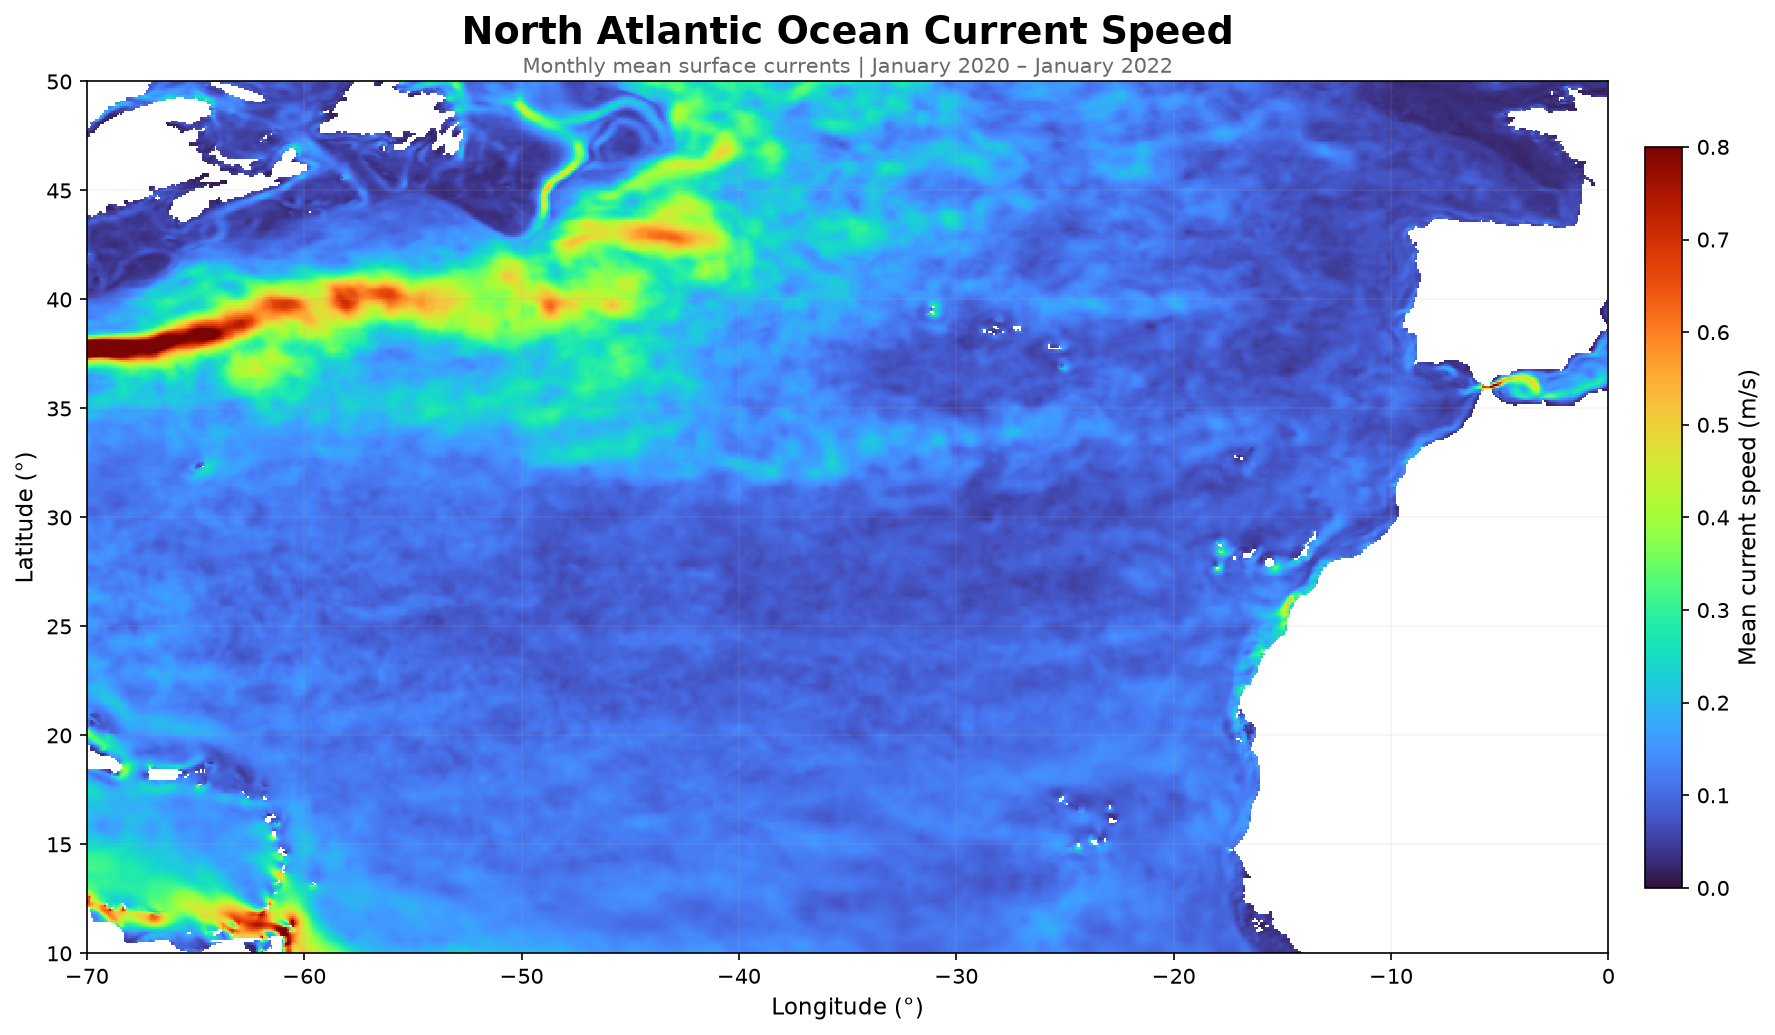

In [41]:
# Average ocean-current speed across 2020–2022
mean_speed = clean_currents["speed"].mean(dim="time")

fig, ax = plt.subplots(figsize=(13, 7), dpi=150)

# Plot ocean-current speed
mesh = ax.pcolormesh(
    mean_speed.longitude,
    mean_speed.latitude,
    mean_speed,
    cmap="turbo",
    shading="auto",
    vmin=0,
    vmax=0.8
)

# Colour bar
cbar = fig.colorbar(mesh, ax=ax, shrink=0.85, pad=0.02)
cbar.set_label("Mean current speed (m/s)", fontsize=11)

# Titles and labels
ax.set_title(
    "North Atlantic Ocean Current Speed",
    fontsize=18,
    fontweight="bold",
    pad=18
)

ax.text(
    0.5, 1.01,
    "Monthly mean surface currents | January 2020 – January 2022",
    transform=ax.transAxes,
    ha="center",
    fontsize=10,
    color="dimgray"
)

ax.set_xlabel("Longitude (°)", fontsize=11)
ax.set_ylabel("Latitude (°)", fontsize=11)

ax.set_xlim(-70, 0)
ax.set_ylim(10, 50)

ax.grid(alpha=0.12)

plt.tight_layout()
plt.show()

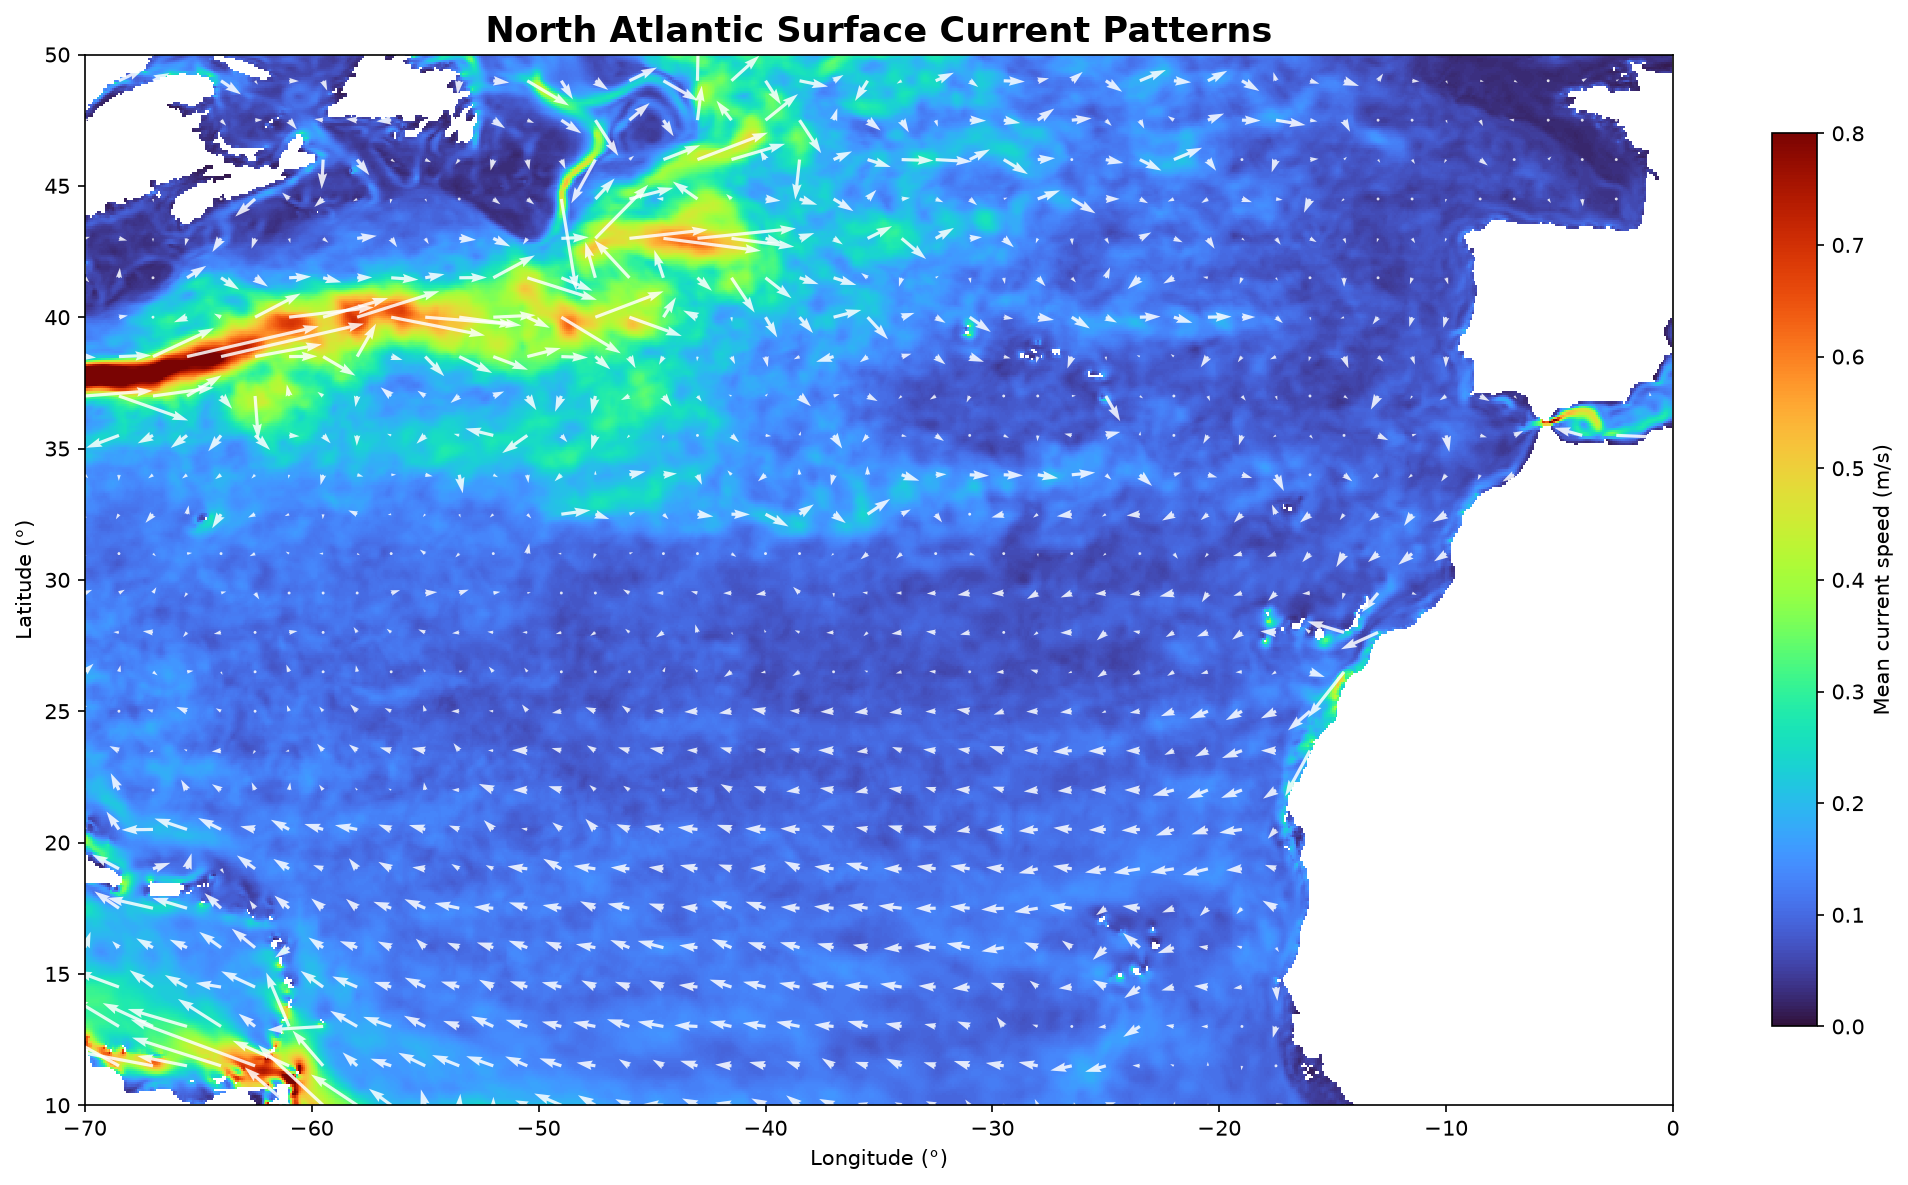

In [42]:
# Average eastward and northward velocities
mean_uo = clean_currents["uo"].mean(dim="time")
mean_vo = clean_currents["vo"].mean(dim="time")

# Reduce arrow density for readability
step = 18

fig, ax = plt.subplots(figsize=(14, 8), dpi=150)

# Background speed map
mesh = ax.pcolormesh(
    mean_speed.longitude,
    mean_speed.latitude,
    mean_speed,
    cmap="turbo",
    shading="auto",
    vmin=0,
    vmax=0.8
)

# Current direction arrows
ax.quiver(
    mean_uo.longitude.values[::step],
    mean_uo.latitude.values[::step],
    mean_uo.values[::step, ::step],
    mean_vo.values[::step, ::step],
    color="white",
    scale=8,
    width=0.002,
    alpha=0.85
)

cbar = fig.colorbar(mesh, ax=ax, shrink=0.85)
cbar.set_label("Mean current speed (m/s)")

ax.set_title(
    "North Atlantic Surface Current Patterns",
    fontsize=17,
    fontweight="bold"
)

ax.set_xlabel("Longitude (°)")
ax.set_ylabel("Latitude (°)")
ax.set_xlim(-70, 0)
ax.set_ylim(10, 50)

plt.tight_layout()
plt.show()

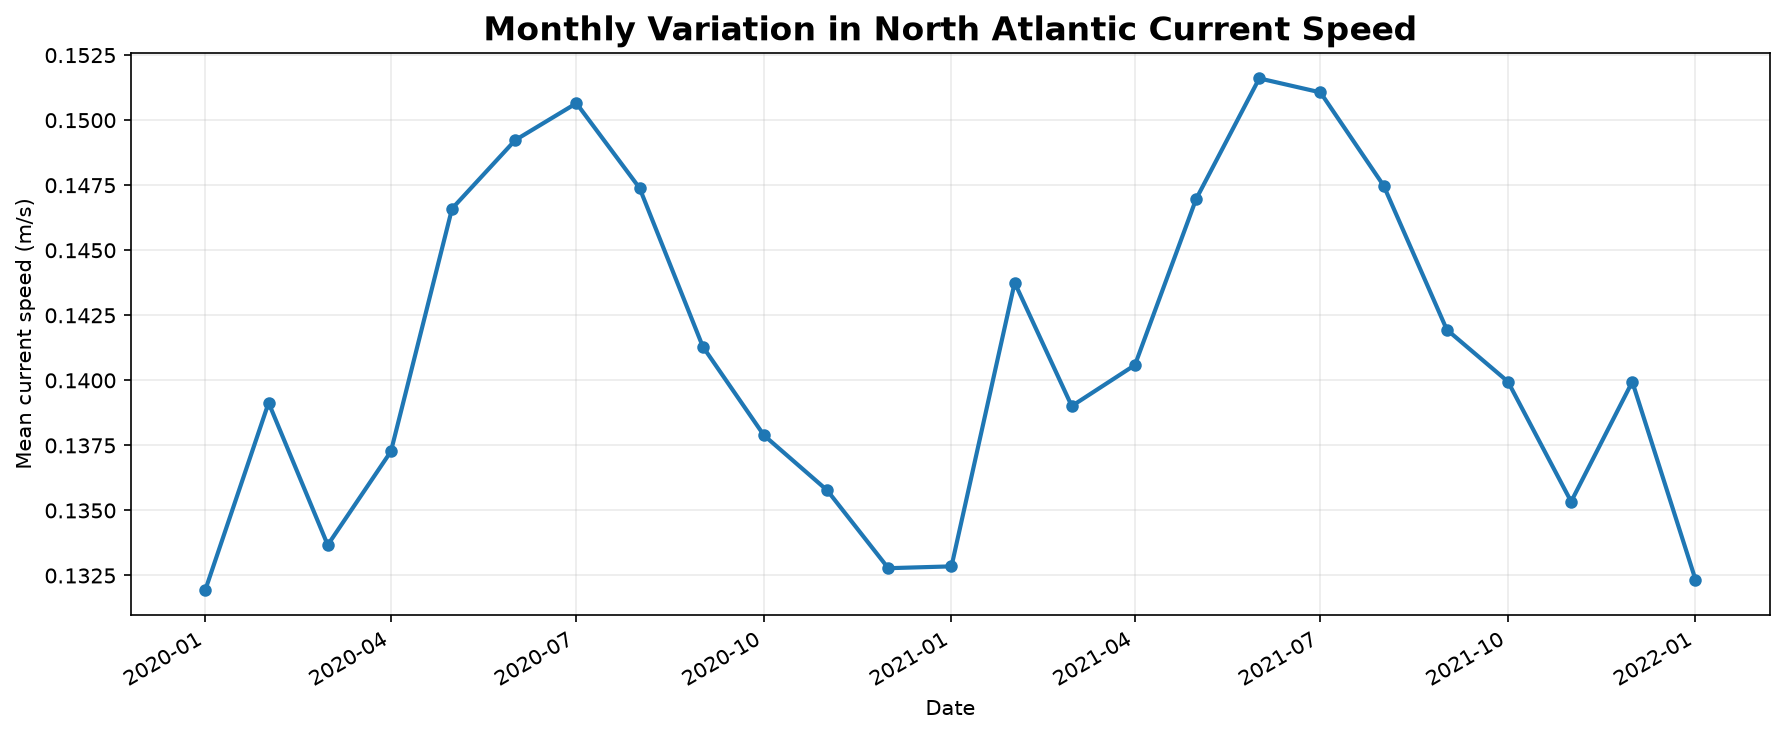

In [43]:
# Calculate spatially averaged current speed for each month
monthly_speed = clean_currents["speed"].mean(
    dim=["latitude", "longitude"]
)

# Convert to DataFrame
monthly_speed_df = monthly_speed.to_dataframe(
    name="Mean current speed"
).reset_index()

# Plot
fig, ax = plt.subplots(figsize=(12, 5), dpi=150)

ax.plot(
    monthly_speed_df["time"],
    monthly_speed_df["Mean current speed"],
    marker="o",
    linewidth=2,
    markersize=5
)

ax.set_title(
    "Monthly Variation in North Atlantic Current Speed",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Date")
ax.set_ylabel("Mean current speed (m/s)")

ax.grid(alpha=0.25)
fig.autofmt_xdate()

plt.tight_layout()
plt.show()

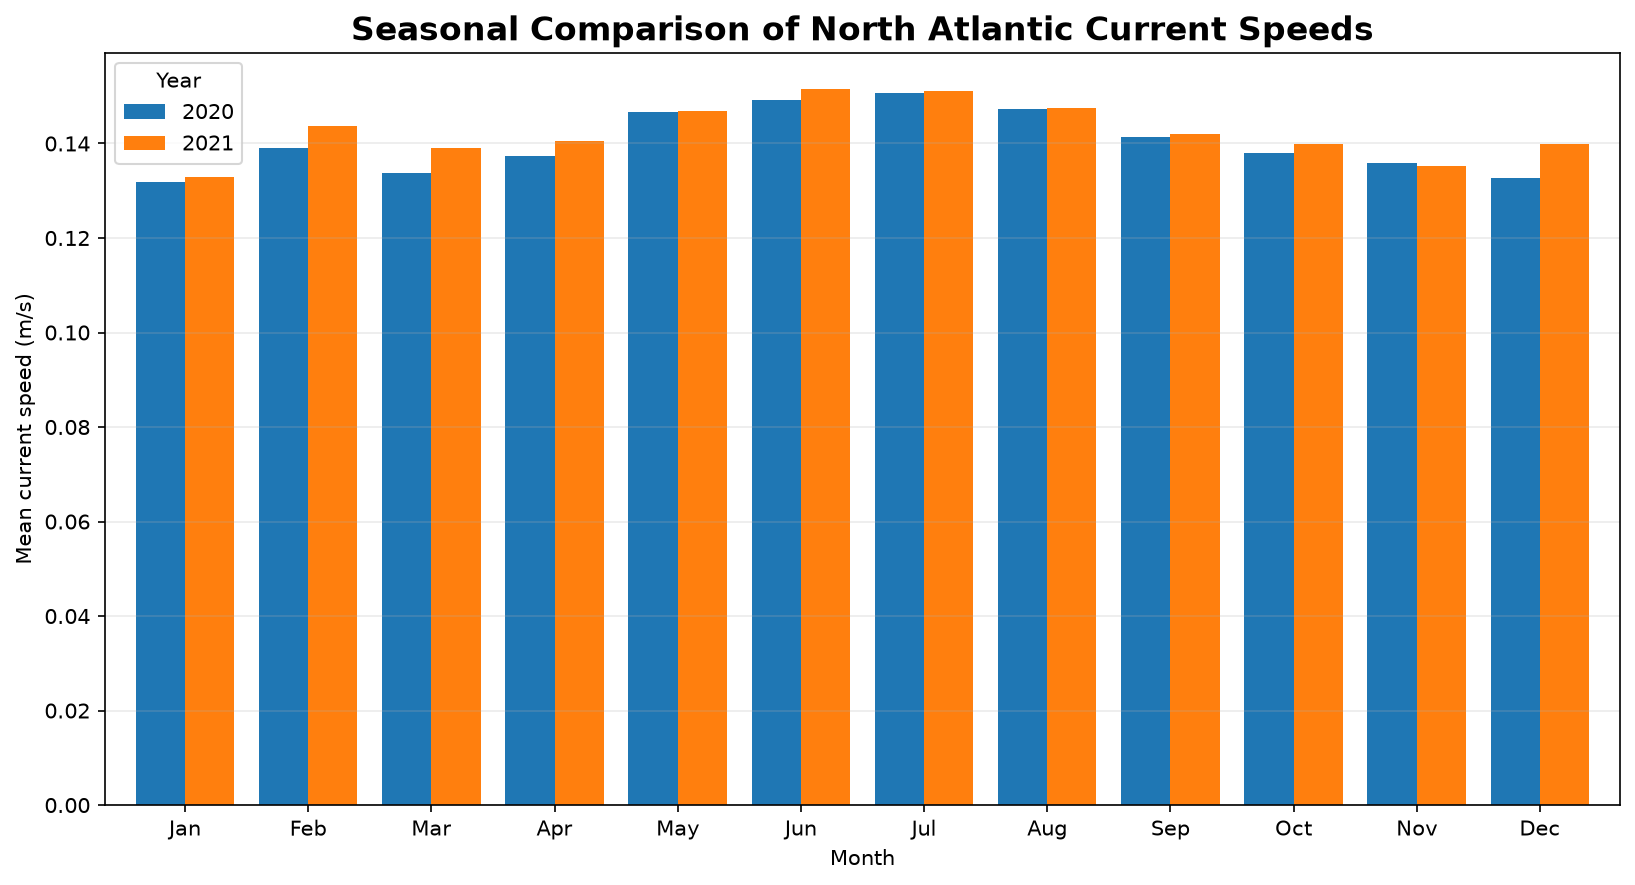

In [44]:
# Extract year and month
monthly_speed_df["year"] = monthly_speed_df["time"].dt.year
monthly_speed_df["month"] = monthly_speed_df["time"].dt.month

# Compare 2020 and 2021
comparison = monthly_speed_df[
    monthly_speed_df["year"].isin([2020, 2021])
].pivot(
    index="month",
    columns="year",
    values="Mean current speed"
)

# Plot comparison
fig, ax = plt.subplots(figsize=(11, 6), dpi=150)

comparison.plot(
    kind="bar",
    ax=ax,
    width=0.8
)

ax.set_title(
    "Seasonal Comparison of North Atlantic Current Speeds",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Month")
ax.set_ylabel("Mean current speed (m/s)")
ax.set_xticklabels(
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
    rotation=0
)

ax.legend(title="Year")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()